# 01 — Resolução de entrada + backbones modernos (fine-tuning completo)

**Pergunta:** o que limita o campeão atual (MobileNetV2 ImageNet congelado, 96×96, Adam)?

**Hipótese principal:** resolução. Os objetos ocupam ~5% da largura da imagem (mediana 33 px em imagens de 416–1024 px); em 96 px viram 2–6 px. Testamos separadamente o efeito de (a) resolução, (b) fine-tuning completo e (c) backbones mais modernos (EfficientNetV2-B0, ConvNeXt-Pico), em 224 e 320 px.

Configuração do fine-tuning: AdamW (lr 2e-4 no backbone, 10× na cabeça, weight decay 0,05), cosine com warmup de 5%, 25 épocas, early stopping (paciência 8), class weight suavizado (0,6) como no notebook original, augmentation padrão (flip horizontal, rotação ±10°, zoom/translação leves, brilho/contraste).

### Protocolo comum (todos os notebooks)
- **Dados:** 1170 imagens side-scan sonar (Marinha Portuguesa, 2010–2021). Rótulo 1 = contém ≥1 **MILCO** (mine-like contact), 255 imagens (21,8%); 0 = só NOMBO ou fundo.
- **Split de triagem (holdout):** estratificado fixo 70/15/15 (seed 42) → treino 819 · validação 175 · teste 176 (38 minas). Mesmo split para todos os experimentos.
- **Seleção do checkpoint:** melhor AUC na **validação** (early stopping). O **threshold** de decisão também é escolhido na validação — o teste só é usado uma vez.
- **Métricas no teste:** ROC-AUC (principal), PR-AUC, F1/precisão/recall com threshold da validação, F1@0.5 e *F1 oráculo* (threshold escolhido no próprio teste, só para comparar com a metodologia do notebook antigo).
- **Atenção:** com 38 positivos no teste, diferenças < ~0,02 de AUC estão dentro do ruído — por isso os finalistas passam por **validação cruzada 5-fold** (notebook 04).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
sys.path.insert(0, str(Path.cwd()))
import sonar_harness as h
import analise as A
fila = json.load(open("fila_experimentos.json"))

In [2]:
# ------------------------------------------------------------------
# (Opcional) Re-treinar os experimentos deste notebook.
# Os resultados abaixo já foram gerados pela fila de execução (máquina local, CPU, treino fatiado).
# Em uma máquina com GPU basta trocar RODAR_TREINO para True: o harness treina de ponta a ponta
# (o mesmo código que roda fatiado também roda sem limite de tempo).
# ------------------------------------------------------------------
RODAR_TREINO = False
GRUPO = "NB01"
jobs = [j for j in fila if j.get("group") == GRUPO]
for j in jobs:
    print(f"{j['id']:45s} {j.get('desc','')}")
if RODAR_TREINO:
    import math
    for j in jobs:
        h.train_job(j, deadline=math.inf)

nb01_baseline_mnv2_96_frozen_adam             Baseline reproduzido: MobileNetV2 ImageNet congelado, Adam 1e-3, 96px, cabeça Keras, aug Keras
nb01_mnv2_96_full_adamw                       Ablação: MobileNetV2 96px com fine-tuning completo (AdamW+cosine)
nb01_mnv2_224_frozen_adam                     Ablação: baseline só aumentando resolução para 224px
nb01_mnv2_224_full_adamw                      MobileNetV2 224px fine-tuning completo
nb01_effv2b0_224_full_adamw                   EfficientNetV2-B0 224px fine-tuning completo
nb01_convnextpico_224_full_adamw              ConvNeXt-Pico 224px fine-tuning completo
nb01_effv2b0_320_full_adamw                   EfficientNetV2-B0 320px fine-tuning completo
nb01_convnextpico_320_full_adamw              ConvNeXt-Pico 320px fine-tuning completo


## Resultados no teste do holdout

In [3]:
runs = A.load_runs("nb01_")
df = A.tabela(runs)
df

,experimento,backbone,res,treino,otimizador,loss,aug,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val),F1@0.5,F1 oráculo,épocas,treino (min),inferência (ms/img CPU)
0,nb01_convnextpico_320_full_adamw,convnext_pico,320,full,adamw,bce,standard,0.961,0.872,0.843,0.778,0.921,0.843,0.886,25,61.585,59.839
1,nb01_effv2b0_224_full_adamw,tf_efficientnetv2_b0,224,full,adamw,bce,standard,0.957,0.882,0.771,0.844,0.711,0.765,0.818,21,24.502,17.384
2,nb01_effv2b0_320_full_adamw,tf_efficientnetv2_b0,320,full,adamw,bce,standard,0.954,0.852,0.800,0.723,0.895,0.805,0.810,25,48.386,38.686
3,nb01_convnextpico_224_full_adamw,convnext_pico,224,full,adamw,bce,standard,0.948,0.872,0.835,0.805,0.868,0.786,0.835,25,30.359,24.055
4,nb01_mnv2_224_frozen_adam,mobilenetv2_100,224,frozen,adam,bce,baseline,0.917,0.783,0.716,0.828,0.632,0.686,0.730,20,7.576,15.874
5,nb01_mnv2_224_full_adamw,mobilenetv2_100,224,full,adamw,bce,standard,0.911,0.793,0.729,0.660,0.816,0.757,0.789,25,31.620,18.986
6,nb01_baseline_mnv2_96_frozen_adam,mobilenetv2_100,96,frozen,adam,bce,baseline,0.909,0.805,0.735,0.833,0.658,0.727,0.753,19,0.927,2.333
7,nb01_mnv2_96_full_adamw,mobilenetv2_100,96,full,adamw,bce,standard,0.871,0.762,0.694,0.735,0.658,0.633,0.694,25,4.445,2.655


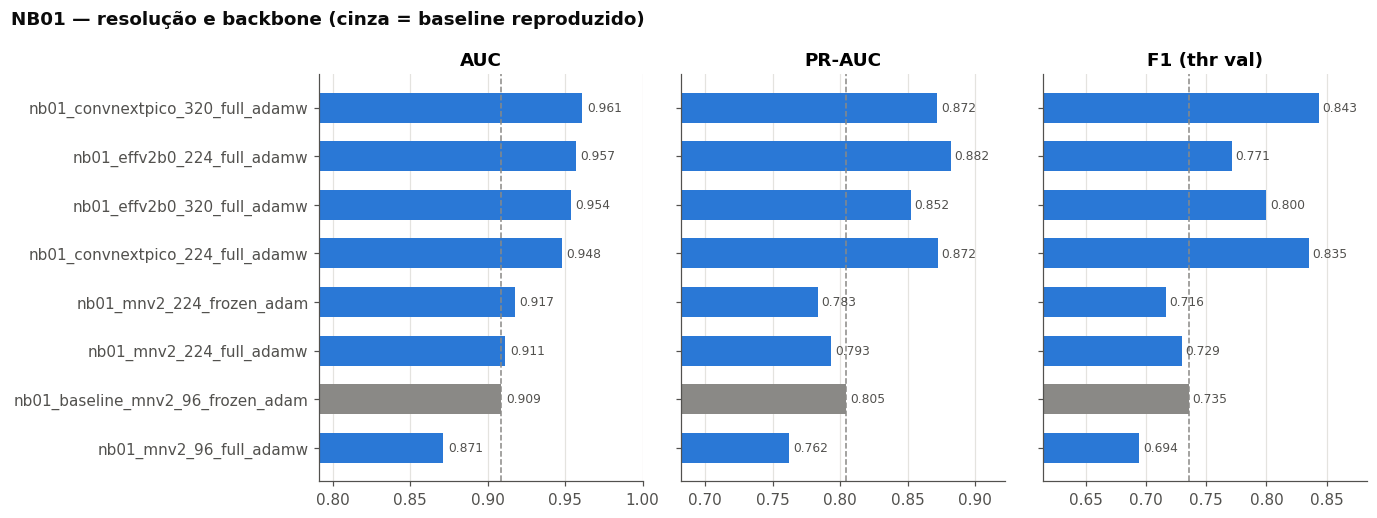

In [4]:
A.barras(df, titulo="NB01 — resolução e backbone (cinza = baseline reproduzido)", arquivo="nb01_barras.png");

### Com TTA (média com a imagem espelhada horizontalmente)

In [5]:
A.tabela(runs, tta=True)[["experimento","AUC","PR-AUC","F1 (thr val)","Precisão (thr val)","Recall (thr val)"]]

,experimento,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val)
0,nb01_convnextpico_320_full_adamw,0.964,0.878,0.921,0.921,0.921
1,nb01_effv2b0_320_full_adamw,0.956,0.850,0.833,0.761,0.921
2,nb01_effv2b0_224_full_adamw,0.950,0.867,0.795,0.829,0.763
3,nb01_convnextpico_224_full_adamw,0.943,0.861,0.784,0.806,0.763
4,nb01_mnv2_224_full_adamw,0.923,0.818,0.725,0.623,0.868
5,nb01_mnv2_224_frozen_adam,0.920,0.789,0.686,0.750,0.632
6,nb01_baseline_mnv2_96_frozen_adam,0.894,0.788,0.720,0.730,0.711
7,nb01_mnv2_96_full_adamw,0.888,0.778,0.625,0.769,0.526


## Curvas de aprendizado

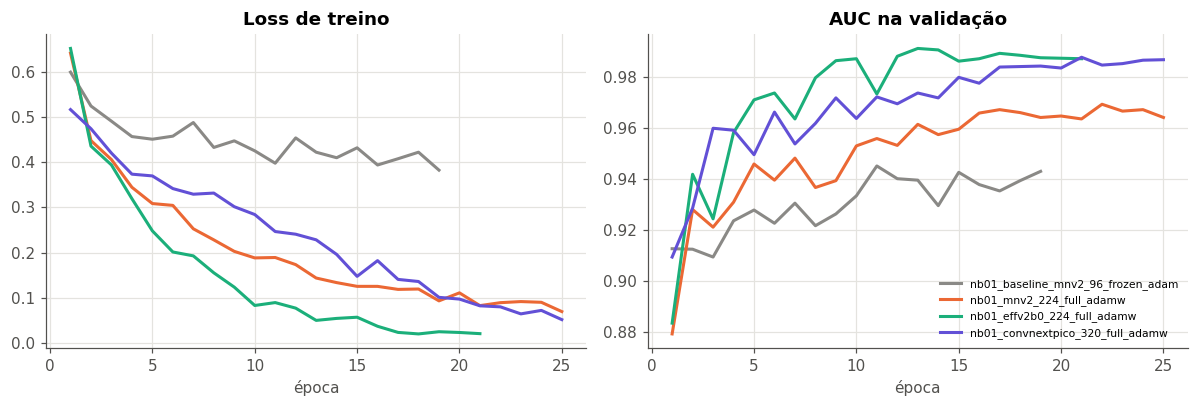

In [6]:
ids = ["nb01_baseline_mnv2_96_frozen_adam", "nb01_mnv2_224_full_adamw", "nb01_effv2b0_224_full_adamw", "nb01_convnextpico_320_full_adamw"]
A.curvas_treino(runs, ids, arquivo="nb01_curvas.png");

## ROC e Precisão × Recall

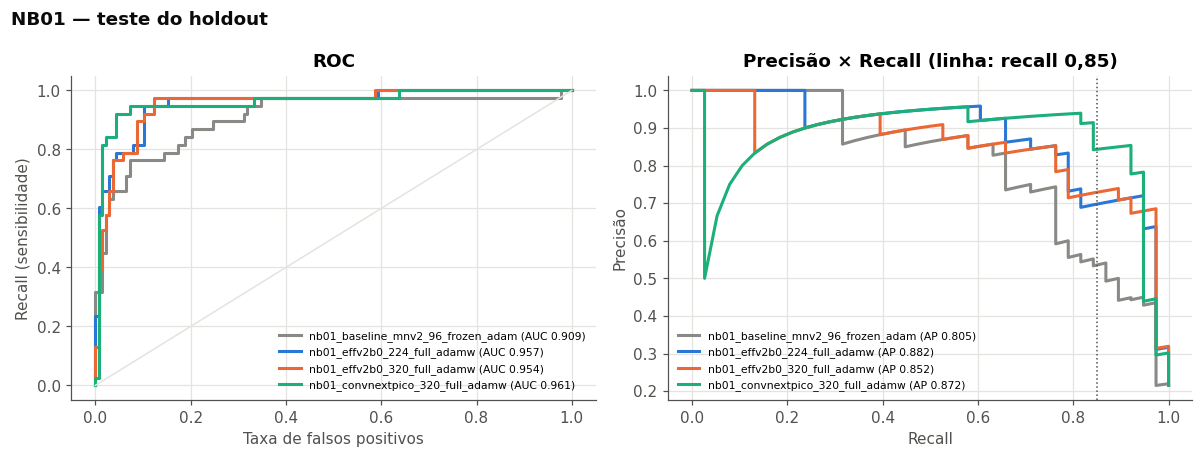

In [7]:
A.roc_pr(["nb01_baseline_mnv2_96_frozen_adam", "nb01_effv2b0_224_full_adamw", "nb01_effv2b0_320_full_adamw", "nb01_convnextpico_320_full_adamw"],
         titulo="NB01 — teste do holdout", arquivo="nb01_roc_pr.png");

## Leitura
- **Baseline reproduzido** no harness: AUC ≈ 0,91 (o notebook original reportou 0,898 em outro split) — confirma que o harness é comparável.
- **Só aumentar a resolução** (96→224) com a base congelada quase não muda nada; **só fazer fine-tuning** em 96 px piora (overfitting com objetos minúsculos).
- O salto vem da **combinação backbone moderno + fine-tuning completo + resolução ≥ 224**: EfficientNetV2-B0 e ConvNeXt-Pico sobem para AUC ≈ 0,95–0,96 e PR-AUC ≈ 0,85–0,88.
- 320 px ajuda o ConvNeXt-Pico (melhor F1 do grupo), mas custa ~2× o tempo de treino.